# Section 4.1 – Representational Distortion

## Operational Evaluation of Representational Integrity

### Project

Operational Evaluation of Governance Risks in Simulated Subjecthood

## Objective

The objective of this notebook is to evaluate representational distortion within the dataset by measuring how closely demographic group distributions align with a predefined reference distribution.

This analysis operationalises the concept of representational integrity introduced in Section 4.1 of the paper and establishes the empirical basis for assessing governance risks arising from dataset composition.

## Research Question

Does the dataset exhibit representational distortion that could influence downstream governance decisions made using simulated subjects?

## Theory Link

Representational distortion is one of the primary governance risks discussed in Section 4.1 of the paper. If certain demographic groups are systematically underrepresented or overrepresented, models trained on the dataset may encode these distortions, leading to inequitable governance outcomes.

This notebook operationalises that theoretical concept using the Representational Integrity Index (RII).

## Dataset Description

Dataset: Heart Disease Prediction Dataset

Variables analysed in this notebook:

- Sex
- HeartDisease

The variable **Sex** is used to demonstrate the calculation of the Representational Integrity Index (RII) against a balanced reference distribution.

In [1]:
#Imports
import sys
from pathlib import Path

# Make the project root importable when running from /notebooks
sys.path.append(str(Path.cwd().parent))

import pandas as pd

from src.config import (
    HEART_DATA_PATH,
    TABLES_DIR,
)

from src.utils import (
    load_data,
    save_dataframe,
)

from src.rii import (
    calculate_group_distribution,
    create_reference_distribution,
    calculate_rii,
    create_rii_metrics_table,
)

## Configuration

This notebook uses the project-wide configuration defined in `config.py`.

Configuration includes:

- Dataset paths
- Output directories
- Reproducible project settings

In [2]:
#Data Loading
df = load_data(HEART_DATA_PATH)

df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Data Audit

Before calculating representational integrity, we verify the dataset dimensions and inspect the variables used in this experiment.

In [3]:
#Dataset Check
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

df[["Sex", "HeartDisease"]].head()

Rows: 918
Columns: 12


,Sex,HeartDisease
0,M,0
1,F,1
2,M,0
3,F,1
4,M,0


## Preprocessing

No additional preprocessing is required for this experiment because the variable **Sex** is already categorical and contains no missing values.

In [4]:
#Calculate Observed Distribution
observed = calculate_group_distribution(
    dataframe=df,
    column="Sex"
)

observed

Sex
F    0.21024
M    0.78976
Name: proportion, dtype: float64

In [5]:
#Create Reference Distribution
reference = create_reference_distribution(
    ["F", "M"]
)

reference

F    0.5
M    0.5
dtype: float64

In [6]:
#Calculate RII
rii = calculate_rii(
    observed_distribution=observed,
    reference_distribution=reference,
)

print(f"Representational Integrity Index (RII): {rii:.3f}")

Representational Integrity Index (RII): 0.710


## Results

The Representational Integrity Index (RII) is calculated using the observed distribution of the **Sex** variable and a balanced reference distribution.

The resulting metric provides a quantitative measure of representational integrity within the dataset.

In [7]:
#Create Table 2
rii_table = create_rii_metrics_table(
    variable="Sex",
    rii=rii
)

rii_table

,Variable,Representational Integrity Index
0,Sex,0.71


In [8]:
#Save Table 2
save_dataframe(
    rii_table,
    TABLES_DIR / "table_2_representational_integrity_metrics.csv"
)

print("Table 2 saved successfully.")

Table 2 saved successfully.


## Interpretation

The calculated Representational Integrity Index (RII) for the **Sex** variable is **0.710**.

This indicates that the observed distribution differs substantially from the balanced reference distribution, reflecting moderate representational distortion.

Such imbalance may propagate into downstream machine learning models and influence governance decisions if not recognised and appropriately managed.

This finding supports the theoretical argument presented in Section 4.1 that representational distortion constitutes an upstream governance risk.

## Save Outputs

The publication-ready metrics table has been automatically generated and saved to the project output directory for subsequent use in reporting and dashboard visualisation.

## Conclusion

This notebook operationalised the concept of representational integrity by computing the Representational Integrity Index (RII) for the **Sex** variable.

The analysis demonstrated measurable representational imbalance relative to the chosen reference distribution. The generated metric provides a reproducible foundation for assessing governance risks arising from dataset composition.

The outputs generated in this notebook will be used in subsequent governance experiments and incorporated into the final publication artefacts.

## Representation Distribution

To visualise representational distortion, the observed distribution of the demographic variable **Sex** is plotted.

This figure complements the Representational Integrity Index (RII) by providing a visual representation of the dataset composition.

In [ ]:
#Import to Generate Figure 2
from src.visualisation import plot_representation_distribution

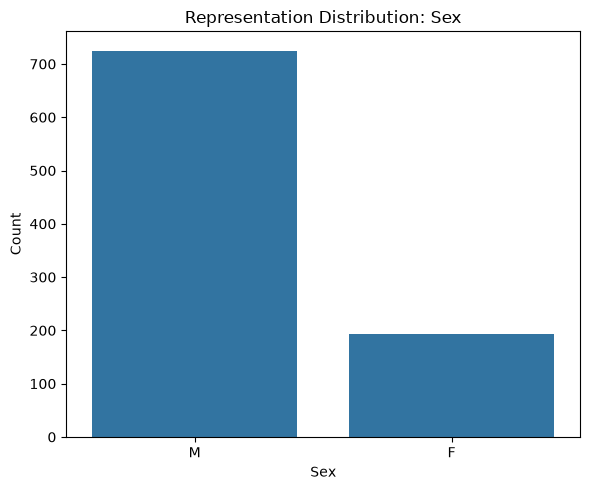

In [10]:
#Generate Figure 2
plot_representation_distribution(
    dataframe=df,
    column="Sex",
    output_path=TABLES_DIR.parent / "figures" / "figure_2_representation_distribution.png"
)

OR

In [11]:
from src.config import FIGURES_DIR

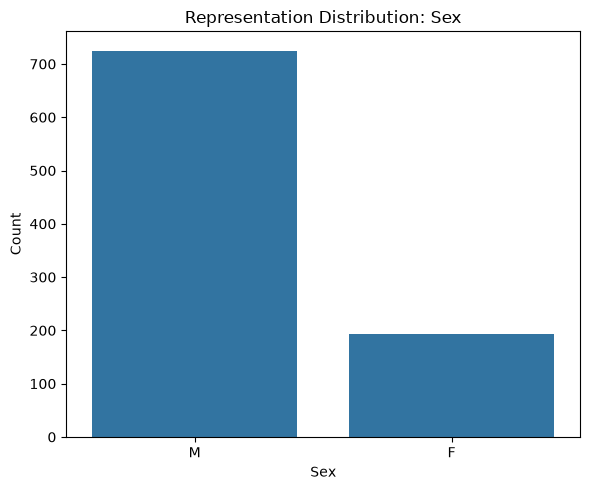

In [12]:
plot_representation_distribution(
    dataframe=df,
    column="Sex",
    output_path=FIGURES_DIR / "figure_2_representation_distribution.png"
)

## Missingness Analysis

The completeness of the dataset is evaluated to determine whether missing values could affect representational integrity.

Both numerical summaries and a missingness heatmap are used to verify data quality.

In [13]:
#Missing Values
from src.preprocessing import check_missing_values

missing_values = check_missing_values(df)

missing_values

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

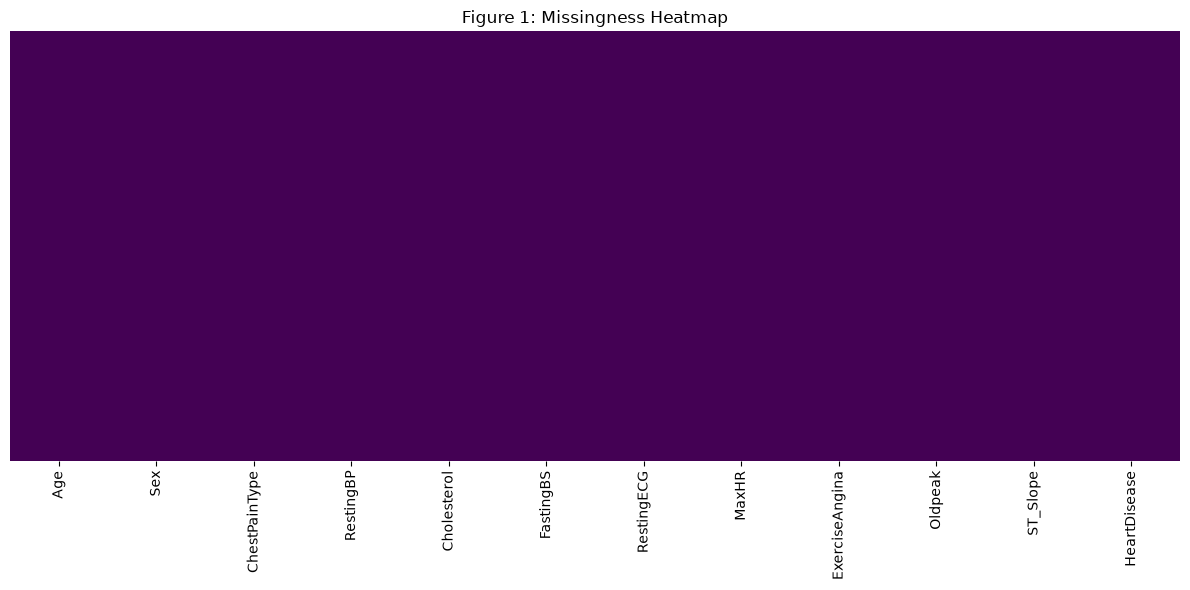

In [14]:
#Missingness Heatmap
from src.visualisation import plot_missingness_heatmap
from src.config import FIGURES_DIR

plot_missingness_heatmap(
    dataframe=df,
    output_path=FIGURES_DIR / "figure_1_missingness_heatmap.png"
)

### Missingness Interpretation

No missing values were detected in the dataset.

Consequently, no imputation procedures were required prior to calculating the Representational Integrity Index (RII). This reduces the likelihood that missing data influenced the representational assessment.

## Robustness Analysis

To evaluate the sensitivity of the Representational Integrity Index (RII), the metric is calculated using alternative reference distributions.

This assesses whether conclusions regarding representational distortion remain stable under different governance assumptions.

In [15]:
#Sensitivity Analysis
balanced_reference = create_reference_distribution(["F", "M"])

observed_reference = observed.copy()

rii_balanced = calculate_rii(
    observed,
    balanced_reference
)

rii_observed = calculate_rii(
    observed,
    observed_reference
)

comparison = pd.DataFrame({
    "Reference": [
        "Balanced (50/50)",
        "Observed Distribution"
    ],
    "RII": [
        round(rii_balanced, 3),
        round(rii_observed, 3)
    ]
})

comparison

,Reference,RII
0,Balanced (50/50),0.71
1,Observed Distribution,1.00


### Robustness Interpretation

As expected, the Representational Integrity Index equals **1.000** when the observed distribution is used as its own reference distribution.

Using a balanced reference distribution produces an RII of **0.710**, indicating measurable representational imbalance.

This sensitivity analysis demonstrates that the RII responds appropriately to changes in the assumed reference population while remaining mathematically consistent.